In [2]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import pandas as pd

In [3]:
#a)
from cargar_datos_tomografia import cargar_datos_tomografia

datos = cargar_datos_tomografia("datos_tomografia_final_128.npz")

A = datos["A"]
b = datos["b"]
n = datos["n"]
angulos = datos["angulos"]
posiciones_detector = datos["posiciones_detector"]

K = len(angulos)
q = len(posiciones_detector)

print("n =", n)
print("K =", K)
print("q =", q)

print("Dimensiones de A:", A.shape)
print("Dimensiones de b:", b.shape)

print("Dimensiones esperadas de A:", (K*q, n**2))
print("Dimensiones esperadas de b:", (K*q,))

print("A tiene dimensiones correctas:", A.shape == (K*q, n**2))
print("b tiene dimensiones correctas:", b.shape == (K*q,))

n = 128
K = 90
q = 183
Dimensiones de A: (16470, 16384)
Dimensiones de b: (16470,)
Dimensiones esperadas de A: (16470, 16384)
Dimensiones esperadas de b: (16470,)
A tiene dimensiones correctas: True
b tiene dimensiones correctas: True


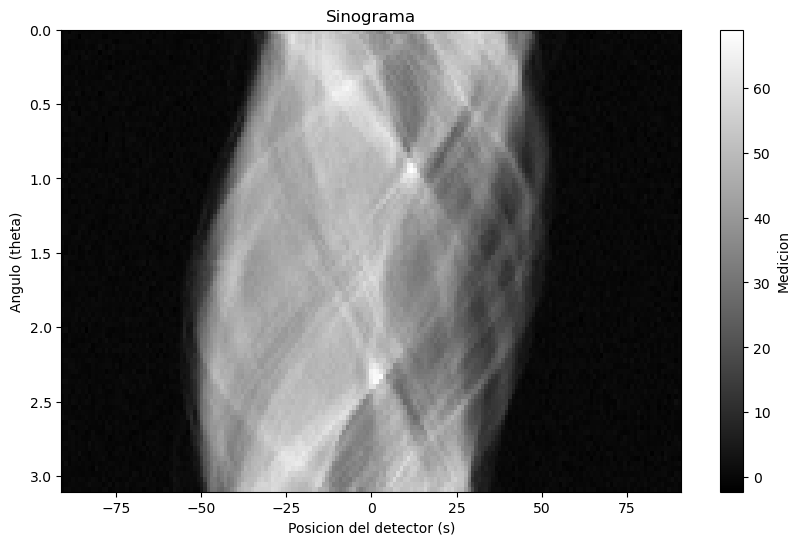

In [4]:
#b)
S = b.reshape(K, q)

plt.figure(figsize=(10, 6))

plt.imshow(
    S,
    aspect="auto",
    cmap="gray",
    extent=[
        posiciones_detector[0],
        posiciones_detector[-1],
        angulos[-1],
        angulos[0]
    ]
)

plt.xlabel("Posicion del detector (s)")
plt.ylabel("Angulo (theta)")
plt.title("Sinograma")

plt.colorbar(label="Medicion")

plt.show()

In [5]:
#c)
from scipy.sparse import csr_matrix

def matriz_diferencias_dispersa(n):

    filas = []
    columnas = []
    valores = []

    fila_actual = 0

    # Diferencias horizontales
    for i in range(n):
        for j in range(n - 1):

            k = i * n + j

            filas.append(fila_actual)
            columnas.append(k)
            valores.append(-1)

            filas.append(fila_actual)
            columnas.append(k + 1)
            valores.append(1)

            fila_actual += 1

    # Diferencias verticales
    for i in range(n - 1):
        for j in range(n):

            k = i * n + j

            filas.append(fila_actual)
            columnas.append(k)
            valores.append(-1)

            filas.append(fila_actual)
            columnas.append(k + n)
            valores.append(1)

            fila_actual += 1

    D = csr_matrix(
        (valores, (filas, columnas)),
        shape=(2 * n * (n - 1), n**2)
    )

    return D


D = matriz_diferencias_dispersa(n)

print("Dimensiones de D:", D.shape)
print("Dimensiones esperadas:", (2 * n * (n - 1), n**2))

print("Cantidad de valores no nulos:", D.nnz)

no_nulos_por_fila = np.diff(D.indptr)

print("Todas las filas tienen exactamente 2 valores no nulos:",
      np.all(no_nulos_por_fila == 2))

Dimensiones de D: (32512, 16384)
Dimensiones esperadas: (32512, 16384)
Cantidad de valores no nulos: 65024
Todas las filas tienen exactamente 2 valores no nulos: True


Iteraciones: 3000
Costo final: 899.8469520605131


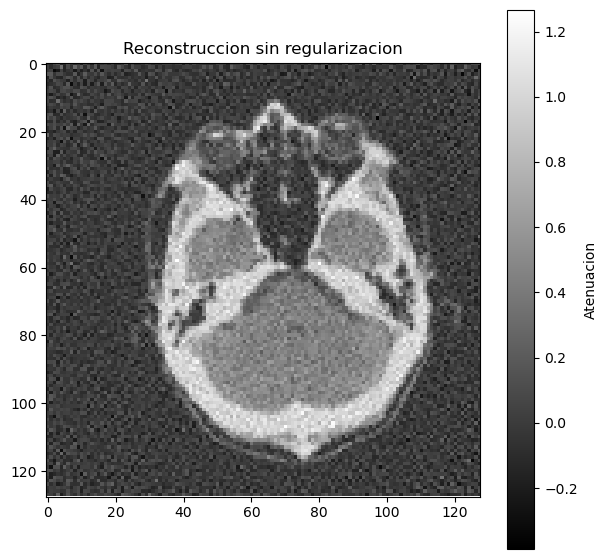

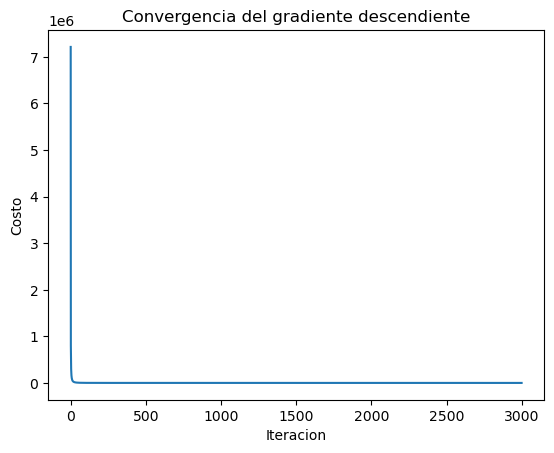

In [6]:
#d)
import matplotlib.pyplot as plt

# funcion de costo
def E(x):
    residuo = A @ x - b
    return 0.5 * np.linalg.norm(residuo)**2


# gradiente
def gradE(x):
    return A.T @ (A @ x - b)


# punto inicial
x = np.zeros(n**2)

# tasa de aprendizaje inicial
alfa = 1e-4

# parametros
max_iter = 3000
tolerancia = 1e-6

costos = []

for t in range(max_iter):

    grad = gradE(x)

    costo = E(x)
    costos.append(costo)

    if np.linalg.norm(grad) < tolerancia:
        break

    x = x - alfa * grad


print("Iteraciones:", t + 1)
print("Costo final:", costos[-1])


# convertir el vector reconstruido en imagen
X_reconstruida = x.reshape(n, n)


# visualizar
plt.figure(figsize=(7, 7))

plt.imshow(X_reconstruida, cmap="gray")

plt.title("Reconstruccion sin regularizacion")
plt.colorbar(label="Atenuacion")

plt.show()


# curva del costo
plt.figure()

plt.plot(costos)

plt.xlabel("Iteracion")
plt.ylabel("Costo")
plt.title("Convergencia del gradiente descendiente")

plt.show()

lambda = 0.1 iteraciones = 3000 costo final = 957.4476029938359
lambda = 1 iteraciones = 3000 costo final = 1323.8257038305198
lambda = 10 iteraciones = 2014 costo final = 3244.786559908444
lambda = 30 iteraciones = 822 costo final = 5988.242765050356
lambda = 100 iteraciones = 393 costo final = 11843.091223415026


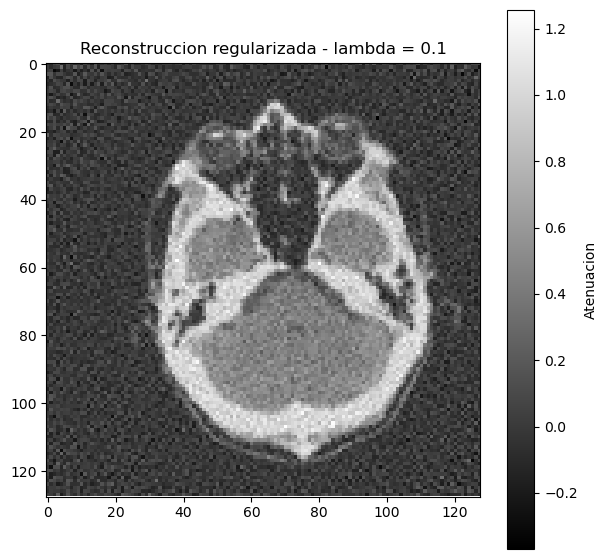

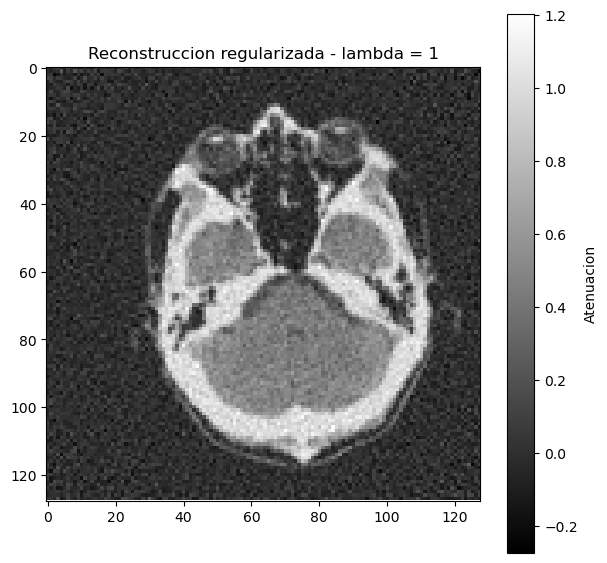

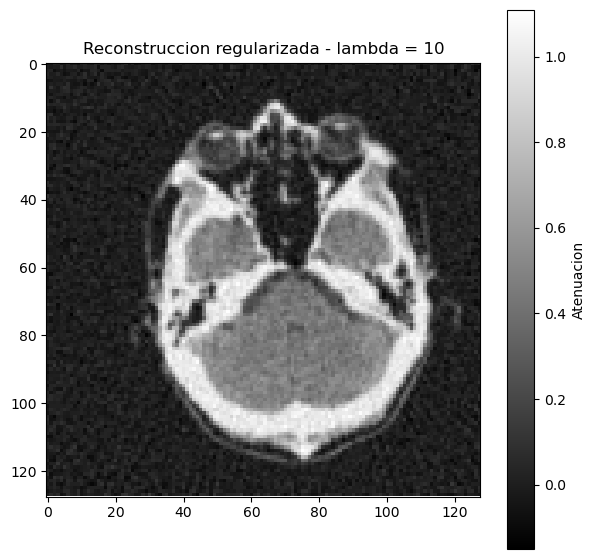

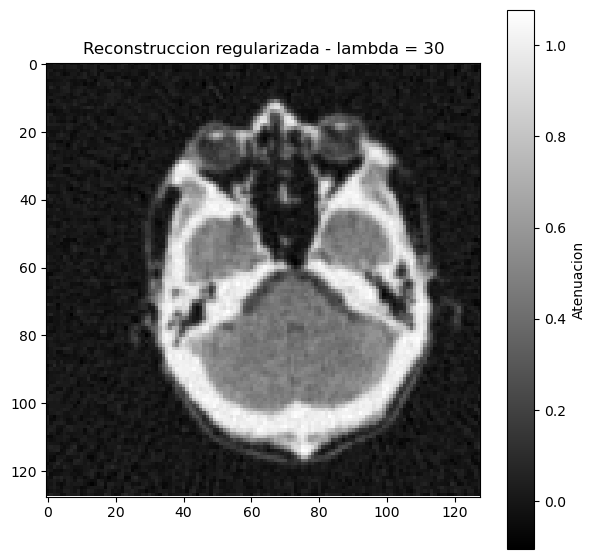

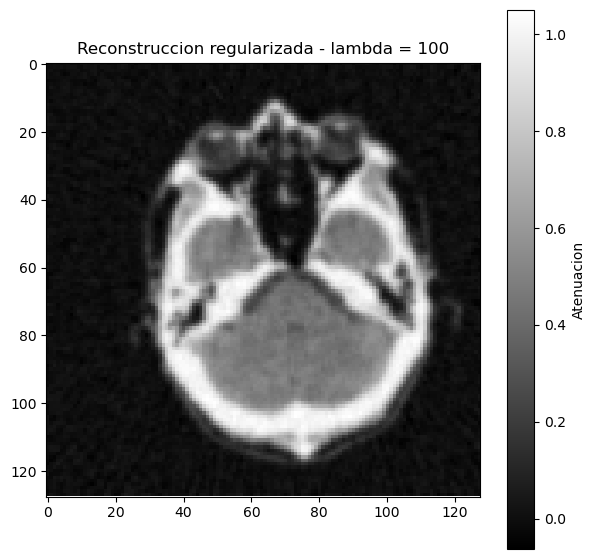


lambda | alfa | iteraciones | norma residuo | ||Dx|| | minimo | maximo
[0.1, 0.0001, 3000, 42.691433041654626, 30.37658387230991, -0.36931473967227685, 1.2561720788590738]
[1, 0.0001, 3000, 44.867894871248836, 25.189609182543386, -0.27361237139704103, 1.2025816890250398]
[10, 0.0001, 2014, 55.3822505682612, 18.49967416418792, -0.15013372020274318, 1.1089121378354856]
[30, 0.0001, 822, 71.53031992924387, 15.121616823740254, -0.10411797126460477, 1.0768598505702467]
[100, 0.0001, 393, 102.62712461879663, 11.469026000192011, -0.06267202326218883, 1.050544040979725]

Norma esperada del ruido: 75.96688842773438
lambda = 0.1 | residuo = 42.691433041654626 | ruido esperado = 75.96688842773438
lambda = 1 | residuo = 44.867894871248836 | ruido esperado = 75.96688842773438
lambda = 10 | residuo = 55.3822505682612 | ruido esperado = 75.96688842773438
lambda = 30 | residuo = 71.53031992924387 | ruido esperado = 75.96688842773438
lambda = 100 | residuo = 102.62712461879663 | ruido esperado = 75.96

In [8]:
# e y f)
import numpy as np
import matplotlib.pyplot as plt


lambdas = [0.1, 1, 10, 30, 100]

reconstrucciones = {}
iteraciones_por_lambda = {}
costos_por_lambda = {}

def J(x, lamb):
    termino_datos = np.linalg.norm(A @ x - b)**2
    termino_regularizacion = lamb * np.linalg.norm(D @ x)**2

    return 0.5 * (termino_datos + termino_regularizacion)


def gradJ(x, lamb):
    return (
        A.T @ (A @ x - b)
        + lamb * D.T @ (D @ x)
    )


max_iter = 3000
tolerancia = 1e-6
alfa = 1e-4


# -------------------------
# 10e - Reconstrucciones
# -------------------------

for lamb in lambdas:

    x = np.zeros(n**2)

    costos = []

    for t in range(max_iter):

        grad = gradJ(x, lamb)

        costo = J(x, lamb)
        costos.append(costo)

        # criterio de parada por norma del gradiente
        if np.linalg.norm(grad) < tolerancia:
            break

        # criterio de parada por variacion del costo
        if t > 0 and abs(costos[-1] - costos[-2]) < 1e-6:
            break

        x = x - alfa * grad

    reconstrucciones[lamb] = x
    iteraciones_por_lambda[lamb] = t + 1
    costos_por_lambda[lamb] = costos

    print(
        "lambda =", lamb,
        "iteraciones =", t + 1,
        "costo final =", costos[-1]
    )


# visualizar reconstrucciones

for lamb in lambdas:

    X = reconstrucciones[lamb].reshape(n, n)

    plt.figure(figsize=(7, 7))
    plt.imshow(X, cmap="gray")
    plt.title(f"Reconstruccion regularizada - lambda = {lamb}")
    plt.colorbar(label="Atenuacion")
    plt.show()


# -------------------------
# 10f - Metricas
# -------------------------

resultados = []

norma_ruido_esperada = datos["norma_ruido_esperada"]

for lamb in lambdas:

    x = reconstrucciones[lamb]

    residuo = A @ x - b
    norma_residuo = np.linalg.norm(residuo)

    variacion = np.linalg.norm(D @ x)

    minimo = np.min(x)
    maximo = np.max(x)

    iteraciones = iteraciones_por_lambda[lamb]

    resultados.append([
        lamb,
        alfa,
        iteraciones,
        norma_residuo,
        variacion,
        minimo,
        maximo
    ])


print("\nlambda | alfa | iteraciones | norma residuo | ||Dx|| | minimo | maximo")

for fila in resultados:
    print(fila)


print("\nNorma esperada del ruido:", norma_ruido_esperada)


for fila in resultados:

    lamb = fila[0]
    norma_residuo = fila[3]

    print(
        "lambda =", lamb,
        "| residuo =", norma_residuo,
        "| ruido esperado =", norma_ruido_esperada
    )

Para el 10f agregamos principalmente tres cosas al código del e: guardamos la cantidad de iteraciones de cada lambda, calculamos para cada reconstrucción la norma del residuo, ||Dx||, el mínimo y el máximo, y finalmente comparamos la norma del residuo con la estimación de ruido incluida en los datos. Eso es exactamente lo que pide la consigna del 10f.

Lambda candidato: 30
Norma esperada del ruido: 75.96688842773438


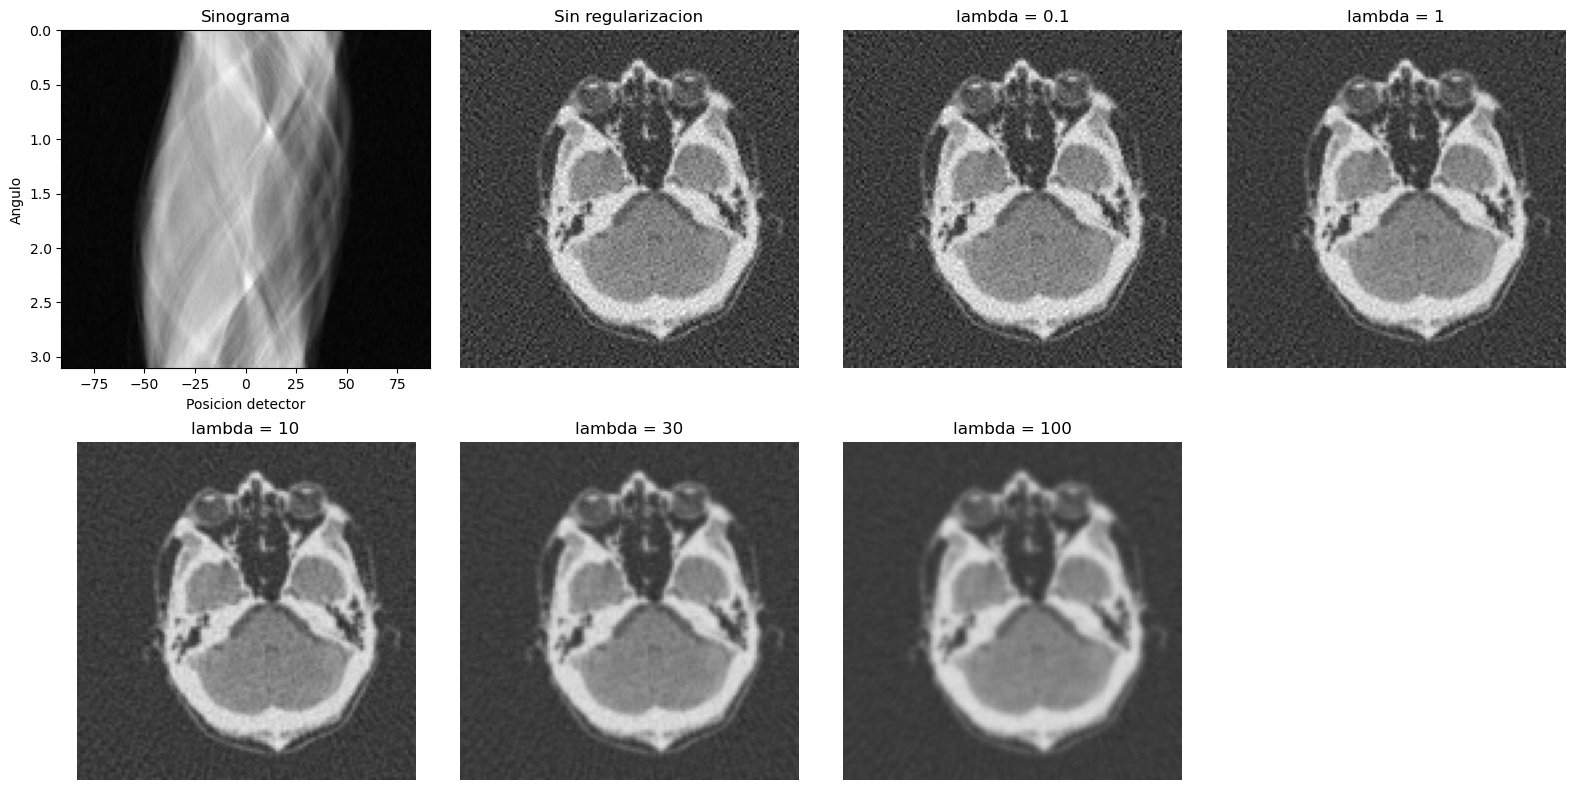


Comparacion:
lambda = 0.1 | residuo = 42.691433041654626 | variacion = 30.37658387230991
lambda = 1 | residuo = 44.867894871248836 | variacion = 25.189609182543386
lambda = 10 | residuo = 55.3822505682612 | variacion = 18.49967416418792
lambda = 30 | residuo = 71.53031992924387 | variacion = 15.121616823740254
lambda = 100 | residuo = 102.62712461879663 | variacion = 11.469026000192011


In [9]:
#g)
import matplotlib.pyplot as plt


# Reconstruccion sin regularizacion del 10d
X_sin_reg = X_reconstruida


# Buscar como candidato el lambda cuyo residuo
# quede mas cerca de la norma esperada del ruido

mejor_lambda = None
menor_diferencia = np.inf

for lamb in lambdas:

    x = reconstrucciones[lamb]

    residuo = A @ x - b
    norma_residuo = np.linalg.norm(residuo)

    diferencia = abs(norma_residuo - norma_ruido_esperada)

    if diferencia < menor_diferencia:
        menor_diferencia = diferencia
        mejor_lambda = lamb


print("Lambda candidato:", mejor_lambda)
print("Norma esperada del ruido:", norma_ruido_esperada)


# Escala de color comun para todas las reconstrucciones

valores = [X_sin_reg.flatten()]

for lamb in lambdas:
    valores.append(reconstrucciones[lamb])

todos = np.concatenate(valores)

vmin = np.min(todos)
vmax = np.max(todos)


# Figura:
# sinograma + sin regularizacion + todas las regularizadas

cantidad_graficos = 2 + len(lambdas)

fig, axes = plt.subplots(
    2,
    4,
    figsize=(16, 8)
)

axes = axes.flatten()


# Sinograma

axes[0].imshow(
    S,
    aspect="auto",
    cmap="gray",
    extent=[
        posiciones_detector[0],
        posiciones_detector[-1],
        angulos[-1],
        angulos[0]
    ]
)

axes[0].set_title("Sinograma")
axes[0].set_xlabel("Posicion detector")
axes[0].set_ylabel("Angulo")


# Sin regularizacion

axes[1].imshow(
    X_sin_reg,
    cmap="gray",
    vmin=vmin,
    vmax=vmax
)

axes[1].set_title("Sin regularizacion")
axes[1].axis("off")


# Reconstrucciones regularizadas

for indice, lamb in enumerate(lambdas):

    X = reconstrucciones[lamb].reshape(n, n)

    axes[indice + 2].imshow(
        X,
        cmap="gray",
        vmin=vmin,
        vmax=vmax
    )

    axes[indice + 2].set_title(f"lambda = {lamb}")
    axes[indice + 2].axis("off")


# Ocultar paneles que sobren

for i in range(cantidad_graficos, len(axes)):
    axes[i].axis("off")


plt.tight_layout()
plt.show()


# Mostrar metricas para justificar la eleccion

print("\nComparacion:")

for lamb in lambdas:

    x = reconstrucciones[lamb]

    norma_residuo = np.linalg.norm(A @ x - b)
    variacion = np.linalg.norm(D @ x)

    print(
        "lambda =", lamb,
        "| residuo =", norma_residuo,
        "| variacion =", variacion
    )


Elegimos la reconstrucción con lambda = 30. Su norma del residuo es aproximadamente 71.53, un valor cercano a la norma esperada del ruido, que es aproximadamente 75.97. Además, visualmente reduce bastante el ruido sin perder demasiadas estructuras de la imagen. Con valores menores de lambda todavía se observa más ruido, mientras que con lambda = 100 la imagen queda demasiado suavizada y se pierden detalles. Por eso lambda = 30 presenta un buen equilibrio entre ajustar las mediciones, reducir el ruido y preservar las estructuras de la imagen.